# 04 - Optimización de hiperparámetros

**Reorganizado el 26/09/2026** a partir de `03_desercion_modelado.ipynb`. Continúa donde termina `03_modelado.ipynb`: búsqueda aleatoria de hiperparámetros de LightGBM (`num_leaves`, `learning_rate`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda`) sobre **validación únicamente** (early stopping, nunca sobre test), comparando la variante A1 (one-hot) contra A2 (categóricas nativas) — empate técnico en PR-AUC, decisión por simplicidad de pipeline documentada en la celda correspondiente. Sigue la comparación de los cuatro niveles en validación (C4) y el análisis de sensibilidad de `umbral_propio_dias` (T3.4, no opcional): reentrenar sin ese bloque para descartar que el modelo esté solo memorizando la regla de etiquetado.

El modelo que sale de aquí (LightGBM A2, hiperparámetros congelados) es el que se evalúa una sola vez sobre test en `05_evaluacion.ipynb`.

## 4. Nivel 3 -- LightGBM: A1 (one-hot) vs. A2 (categoricas nativas)

T3.3 pide comparar A1 y A2 **con busqueda de hiperparametros sobre
validacion, nunca sobre test**. Se hace una busqueda aleatoria de 12
configuraciones para cada variante (semilla fija), con `early_stopping`
monitoreando PR-AUC en validacion (evita sobreajustar el numero de arboles,
sin tocar test).


In [6]:
import lightgbm as lgb

def buscar_lightgbm(Xtr, Xva, variante, n_iter=12, semilla=42):
    rng = np.random.default_rng(semilla)
    grid = [dict(
        num_leaves=int(rng.choice([15, 31, 63, 127])),
        learning_rate=float(rng.choice([0.03, 0.05, 0.08, 0.1])),
        min_child_samples=int(rng.choice([20, 50, 100, 200])),
        subsample=float(rng.choice([0.7, 0.8, 0.9, 1.0])),
        colsample_bytree=float(rng.choice([0.6, 0.8, 1.0])),
        reg_lambda=float(rng.choice([0.0, 0.1, 1.0, 5.0])),
    ) for _ in range(n_iter)]
    filas, mejor = [], None
    for p in grid:
        m = lgb.LGBMClassifier(n_estimators=800, random_state=42, verbosity=-1, **p)
        m.fit(Xtr, y_tr, eval_set=[(Xva, y_va)], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(30, verbose=False)])
        pr = average_precision_score(y_va, m.predict_proba(Xva)[:, 1])
        fila = dict(p); fila["pr_auc_val"] = pr; fila["best_iter"] = m.best_iteration_
        filas.append(fila)
        if mejor is None or pr > mejor[1]:
            mejor = (m, pr, p)
    return pd.DataFrame(filas).sort_values("pr_auc_val", ascending=False), mejor

grid_A1, (modelo_A1, pr_A1, params_A1) = buscar_lightgbm(XA1_tr, XA1_va, "A1")
print("=== LightGBM A1 (one-hot) ===")
print(grid_A1.round(4).to_string(index=False))
print(f"\nmejor A1: {params_A1}  PR-AUC(val)={pr_A1:.4f}")

=== LightGBM A1 (one-hot) ===
 num_leaves  learning_rate  min_child_samples  subsample  colsample_bytree  reg_lambda  pr_auc_val  best_iter
        127           0.08                 50       1.00              0.8         0.1      0.6975         31
        127           0.05                 20       0.80              1.0         0.0      0.6975         55
         15           0.10                100       0.80              0.8         5.0      0.6969         45
         15           0.08                 20       0.70              0.8         5.0      0.6971         55
         63           0.10                100       1.00              0.8         0.0      0.6970         31
        127           0.05                100       0.80              0.6         5.0      0.6968         88
         31           0.03                 20       0.90              1.0         0.0      0.6969        115
        127           0.10                 50       0.90              0.6         5.0      0.6967

In [7]:
grid_A2, (modelo_A2, pr_A2, params_A2) = buscar_lightgbm(XA2_tr, XA2_va, "A2")
print("=== LightGBM A2 (categoricas nativas) ===")
print(grid_A2.round(4).to_string(index=False))
print(f"\nmejor A2: {params_A2}  PR-AUC(val)={pr_A2:.4f}")

=== LightGBM A2 (categoricas nativas) ===
 num_leaves  learning_rate  min_child_samples  subsample  colsample_bytree  reg_lambda  pr_auc_val  best_iter
        127           0.05                 20       0.80              1.0         0.0      0.6975         56
        127           0.08                 50       1.00              0.8         0.1      0.6975         18
         63           0.10                200       0.70              0.8         0.1      0.6974         35
         63           0.05                 20       1.00              0.8         5.0      0.6974         54
         63           0.10                100       1.00              0.8         0.0      0.6973         30
        127           0.05                100       0.80              0.6         5.0      0.6971         40
        127           0.10                 50       0.90              0.6         5.0      0.6971         35
         15           0.10                100       0.80              0.8         5.0

### 4.1 Decision A1 vs. A2

**Empate tecnico:** PR-AUC(val) = 0,6975 en ambas variantes (diferencia en la
cuarta cifra decimal, dentro del ruido de la busqueda aleatoria). Siguiendo
la regla de T3.3 ("decision justificada por metricas, no por preferencia"):
como no hay diferencia de desempeño, se rompe el empate por **simplicidad y
mantenibilidad del pipeline** -- criterio explicito, no preferencia estetica:
A2 usa las categorias nativas de LightGBM (14 columnas) en vez de expandir en
one-hot (18 columnas), por lo que no hay que regenerar columnas binarias si
aparecen categorias nuevas de metodo de pago, y generaliza mejor a mas
categoricas si el dataset crece. **Se elige A2** como representante de
"LightGBM" para el resto del notebook.

In [8]:
modelo_lgbm, params_lgbm = modelo_A2, params_A2
score_lgbm_va = modelo_lgbm.predict_proba(XA2_va)[:, 1]
resultados_val.append(tabla_metricas("LightGBM A2", y_va, score_lgbm_va))
resultados_val.append(tabla_metricas("LightGBM A1", y_va, modelo_A1.predict_proba(XA1_va)[:, 1]))
print("listo: modelo_lgbm = LightGBM A2 (ganador), params:", params_lgbm)

listo: modelo_lgbm = LightGBM A2 (ganador), params: {'num_leaves': 127, 'learning_rate': 0.05, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 1.0, 'reg_lambda': 0.0}

## 5. Comparacion de niveles (validacion, C4)

Los cinco niveles, con las mismas metricas, en la misma particion:


In [9]:
tabla_val = pd.DataFrame(resultados_val)
print(tabla_val.round(4).to_string(index=False))

                 modelo  pr_auc  precision@1%  lift@1%  precision@3%  lift@3%  precision@5%  lift@5%  precision@10%  lift@10%  precision@20%  lift@20%  precision@30%  lift@30%
Nivel 0 - regla recency  0.6592        0.9208   2.2075        0.8866   2.1254        0.8606   2.0632         0.8094    1.9405         0.7234    1.7342         0.6618    1.5866
   Nivel 1 - RFM simple  0.6536        0.9179   2.2005        0.8743   2.0961        0.8498   2.0372         0.7986    1.9144         0.7165    1.7177         0.6585    1.5786
 Logistica (l2, C=0.01)  0.6836        0.9384   2.2497        0.9042   2.1676        0.8891   2.1315         0.8325    1.9957         0.7498    1.7975         0.6833    1.6380
            LightGBM A2  0.6975        0.9589   2.2989        0.9418   2.2579        0.9114   2.1849         0.8520    2.0425         0.7600    1.8220         0.6905    1.6555
            LightGBM A1  0.6975        0.9531   2.2849        0.9443   2.2637        0.9120   2.1863         0.8531    2

**Lectura:** LightGBM (A1≈A2) supera a la logistica en PR-AUC (+0,014,
~+2 puntos porcentuales absolutos, ~2 % relativo) y en **todos** los umbrales
de precision@k / lift, y la logistica a su vez supera con claridad a ambos
baselines en todo el rango. El orden es consistente en las 6 campanas
evaluadas (1 % a 30 % de la base), no es un resultado que dependa de elegir
un k particular.

 decil  lift_lightgbm  lift_logistica
     1          2.043           1.996
     2          1.601           1.599
     3          1.322           1.319
     4          1.122           1.144
     5          1.000           0.952
     6          0.837           0.827
     7          0.706           0.687
     8          0.601           0.600
     9          0.466           0.522
    10          0.301           0.353

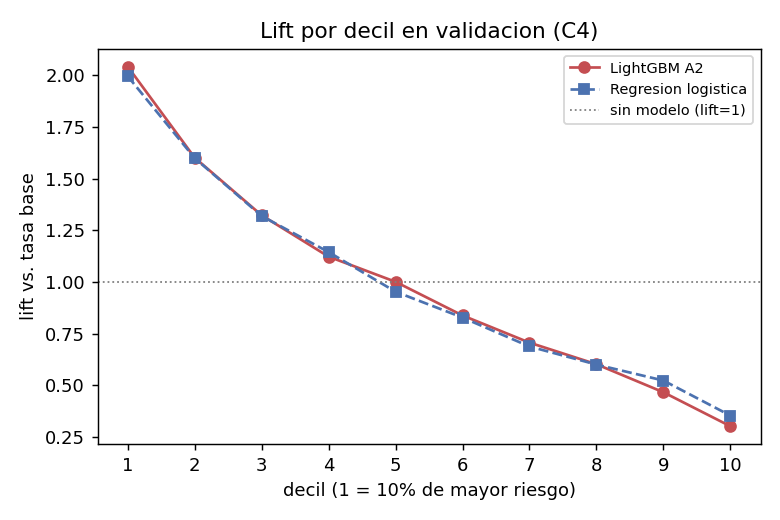

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ld_lgbm = lift_por_decil(y_va, score_lgbm_va)
ld_log  = lift_por_decil(y_va, score_log_va)
ax.plot(ld_lgbm.index + 1, ld_lgbm["lift"], "o-", color="#C44E52", label="LightGBM A2")
ax.plot(ld_log.index + 1, ld_log["lift"], "s--", color="#4C72B0", label="Regresion logistica")
ax.axhline(1.0, color="gray", ls=":", lw=1, label="sin modelo (lift=1)")
ax.set_xlabel("decil (1 = 10% de mayor riesgo)"); ax.set_ylabel("lift vs. tasa base")
ax.set_title("Lift por decil en validacion (C4)"); ax.set_xticks(range(1, 11))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print(pd.concat([ld_lgbm["lift"].rename("lift_lightgbm"), ld_log["lift"].rename("lift_logistica")], axis=1)
      .rename_axis("decil").reset_index().assign(decil=lambda d: d["decil"]+1).round(3).to_string(index=False))

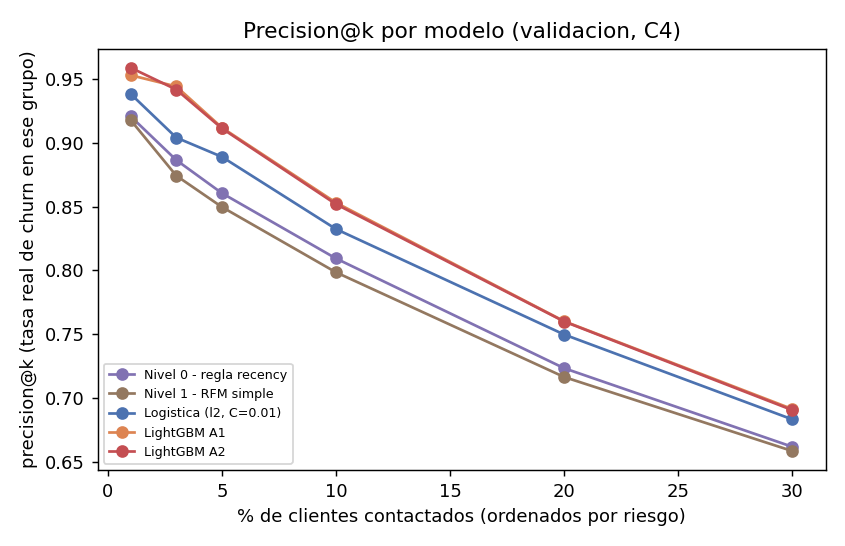

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ks = [1, 3, 5, 10, 20, 30]
colores = {"Nivel 0 - regla recency": "#8172B2", "Nivel 1 - RFM simple": "#937860",
           "Logistica (l2, C=0.01)": "#4C72B0", "LightGBM A1": "#DD8452", "LightGBM A2": "#C44E52"}
for _, row in tabla_val.iterrows():
    ys = [row[f"precision@{k}%"] for k in ks]
    ax.plot(ks, ys, "o-", label=row["modelo"], color=colores.get(row["modelo"]))
ax.set_xlabel("% de clientes contactados (ordenados por riesgo)")
ax.set_ylabel("precision@k (tasa real de churn en ese grupo)")
ax.set_title("Precision@k por modelo (validacion, C4)")
ax.legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

## 6. Analisis de sensibilidad de `umbral_propio_dias` (T3.4, no opcional)

`umbral_propio_dias` participa de la **definicion** de la etiqueta `churn`
(ver `CONTEXTO_PROYECTO.md` seccion 6): no es fuga (se calcula con datos
previos al corte), pero crea una relacion mecanica. Si el modelo solo
aprendiera esa regla de etiquetado y no una señal de fuga real, el
rendimiento se derrumbaria al quitar el bloque.


In [12]:
cols_sin_umbral = [c for c in XA2_tr.columns if c not in BLOQUE_UMBRAL]
m_sin = lgb.LGBMClassifier(n_estimators=800, random_state=42, verbosity=-1, **params_lgbm)
m_sin.fit(XA2_tr[cols_sin_umbral], y_tr, eval_set=[(XA2_va[cols_sin_umbral], y_va)],
          eval_metric="average_precision", callbacks=[lgb.early_stopping(30, verbose=False)])
pr_sin = average_precision_score(y_va, m_sin.predict_proba(XA2_va[cols_sin_umbral])[:, 1])
pr_con = pr_A2
caida_rel = 100 * (pr_con - pr_sin) / pr_con
print(f"PR-AUC CON umbral_propio_dias : {pr_con:.4f}")
print(f"PR-AUC SIN umbral_propio_dias : {pr_sin:.4f}")
print(f"caida relativa: {caida_rel:.2f} %")

PR-AUC CON umbral_propio_dias : 0.6975
PR-AUC SIN umbral_propio_dias : 0.6840
caida relativa: 1.94 %

**Conclusion (criterio de aceptacion T3.4):** la caida es de solo **1,94 %
relativo** al quitar el bloque de umbral -- lejos de un derrumbe. El modelo
retiene casi todo su poder predictivo con las demas features (recency,
actividad, tendencia de gasto, etc.), lo que respalda que **no** esta
simplemente memorizando la regla de etiquetado: hay señal de fuga genuina
en el resto de las variables. Se reporta como hallazgo positivo, no como
limitacion.